# Лабораторна робота №3. Статистичне навчання за динамічним Time Series
Рекурентне згладжування синтетичних даних фільтрами α-β та α-β-γ (групи вимог 1 і 2).

## 1. Вхідні дані
Нормальна похибка N(0, 4) + квадратичний тренд 0.0001·t² (властивості з Лр1).

In [1]:
def rando_norm (dm, dsig, iter):
    S = np.random.normal(dm, dsig, iter)
    mS = np.mean(S)
    dS = np.var(S)
    scvS = mt.sqrt(dS)
    print('------- Статистичні характеристики НОРМАЛЬНОГО закону розподілу ВВ -----')
    print('Матиматичне сподівання ВВ=', mS)
    print('Дисперсія ВВ =', dS)
    print('СКВ ВВ=', scvS)

    print('------------------------------------------------------------------------')
    plt.hist(S, bins=8, facecolor="blue", alpha=0.5, edgecolor="black")
    plt.show()
    return S

------- Статистичні характеристики НОРМАЛЬНОГО закону розподілу ВВ -----
Матиматичне сподівання ВВ= -0.17879885337179385
Дисперсія ВВ = 15.39438219459146
СКВ ВВ= 3.9235675340933613
------------------------------------------------------------------------


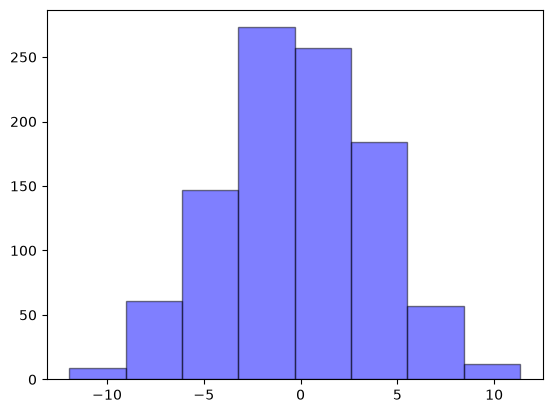

In [2]:
import numpy as np
import math as mt
import matplotlib.pyplot as plt

N = 1000
x = range(N)

normal_sample = rando_norm(0, 4, N)

In [3]:
def square_model(n):
    S0=np.zeros(n)
    for i in range(n):
        S0[i]=(0.0001*i*i)
    return S0
square_y = square_model(N)

In [4]:
additive_square_normal = [x + y for x, y in zip(normal_sample, square_y)]

МНК-модель для порівняння з результатами фільтрації.

In [5]:
def LSM(S0):

    iter = len(S0)
    Yin = np.zeros((iter, 1))
    F = np.ones((iter, 3))

    for i in range(iter):  # формування структури вхідних матриць МНК
        Yin[i, 0] = float(S0[i])  # формування матриці вхідних даних
        F[i, 1] = float(i)
        F[i, 2] = float(i * i)

    FT = F.T
    FFT = FT.dot(F)
    FFTI = np.linalg.inv(FFT)
    FFTIFT = FFTI.dot(FT)
    C = FFTIFT.dot(Yin)
    Yout = F.dot(C)

    print('Регресійна модель:')
    print('y(t) = ', C[0,0], ' + ', C[1,0], ' * t', ' + ', C[2,0], ' * t^2')

    return Yout, C[0,0], C[1,0], C[2,0]


In [6]:
yout, c1, c2, c3 = LSM(additive_square_normal)

Регресійна модель:
y(t) =  0.02403214753926053  +  -0.00116990368792034  * t  +  0.00010114632659033756  * t^2


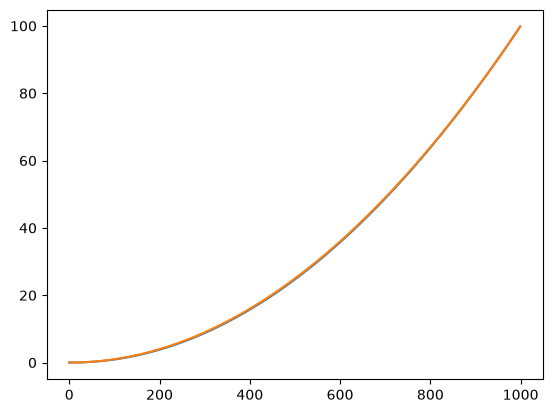

In [7]:
plt.plot(yout)
plt.plot(square_y)
plt.show()

In [8]:
def poly_model_params(t, c1, c2, c3):
    return  c1  +  c2  * t  +  c3  * t ** 2
poly_model = lambda t : poly_model_params(t, c1, c2, c3)

## 2. Аномальні виміри та їх очищення
Додаємо 20 аномалій і прибираємо їх ковзним вікном із заміною на медіану.

In [9]:
def Model_NORM_AV(S0, SV, nAV, Q_AV, dm,  dsig):

    SV_AV = np.copy(SV)
    SSAV = np.random.normal(dm, (Q_AV * dsig), nAV)  # аномальна випадкова похибка з нормальним законом

    SAV = np.random.default_rng().integers(low=0, high = 1000, size = nAV)
    for i in range(nAV):
        k = int(SAV[i])
        SV_AV[k] = S0[k] + SSAV[i]        # аномальні вимірів з рівномірно розподіленими номерами

    return SV_AV


In [10]:
SV_AV = Model_NORM_AV(square_y, additive_square_normal, 20, 0.6, 0, 1)

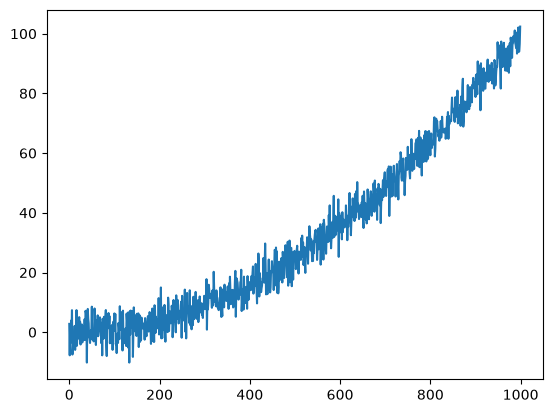

In [11]:
plt.plot(SV_AV)
plt.show()

In [12]:
def Sliding_Window_AV_Detect_medium(S0, n_Wind, Q):
    iter = len(S0)
    j_Wind=mt.ceil(iter-n_Wind)+1
    S0_Wind=np.zeros((n_Wind))

    j = 0
    for i in range(n_Wind):
        l = (j + i)
        S0_Wind[i] = S0[l]
        dS_standart = np.var(S0_Wind)
        scvS_standart = mt.sqrt(dS_standart)


    for j in range(j_Wind):
        for i in range(n_Wind):
            l=(j+i)
            S0_Wind[i] = S0[l]

        mS = np.median(S0_Wind)
        dS = np.var(S0_Wind)
        scvS = mt.sqrt(dS)

        if scvS > (Q * scvS_standart):
            S0[l] = mS

    return S0

In [13]:
cleaned = Sliding_Window_AV_Detect_medium(SV_AV, 50, 1.5 )

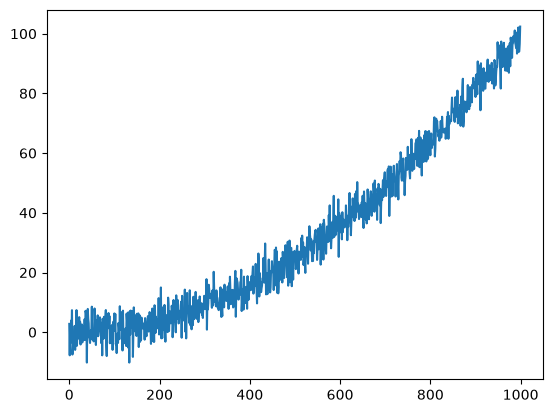

In [14]:
plt.plot(cleaned)
plt.show()

## 3. α-β фільтр
Фільтр оцінює рівень і швидкість процесу. Коефіцієнти α і β зменшуються з кожним кроком, тобто «пам'ять» фільтра зростає.

In [15]:
def ABF(S0):

    iter = len(S0)
    Yin = np.zeros((iter, 1))
    YoutAB = np.zeros((iter, 1))
    T0 = 1

    for i in range(iter):
        Yin[i, 0] = float(S0[i])

    Yspeed_retro = (Yin[1, 0] - Yin[0, 0]) / T0
    Yextra = Yin[0, 0] + Yspeed_retro
    alfa = 2 * (2 * 1 - 1) / (1 * (1 + 1))
    beta = 6 / (1 * (1 + 1))
    YoutAB[0, 0] = Yin[0, 0] + alfa * (Yin[0, 0])

    for i in range(1, iter):
        YoutAB[i, 0] = Yextra + alfa * (Yin[i, 0] - Yextra)
        Yspeed = Yspeed_retro + (beta/T0) * (Yin[i, 0] - Yextra)
        Yspeed_retro = Yspeed
        Yextra = YoutAB[i,0] + Yspeed_retro
        alfa = (2 * (2 * i - 1)) / (i * (i + 1))
        beta = 6 / (i * (i + 1))

    return YoutAB

In [16]:
filtered_ab = ABF(cleaned)
mean_error = filtered_ab - square_y
np.mean(mean_error)

np.float64(-5.786815627839065)

Середня похибка ≈ −5.8, тобто оцінка зміщена. α-β фільтр розрахований на лінійний процес, а тренд квадратичний, тому з часом фільтр дедалі більше відстає (ефект розходження).

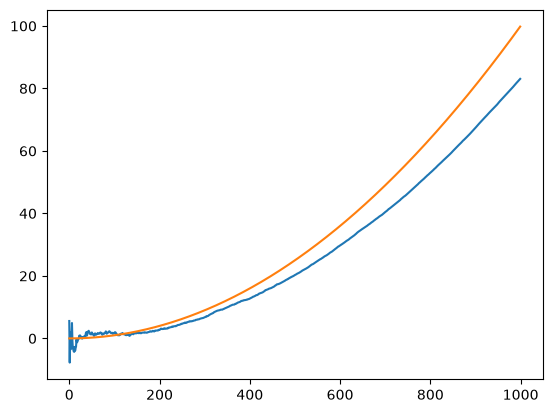

In [17]:
plt.plot(filtered_ab)
plt.plot(square_y)
plt.show()

## 4. Модифікація: α-β-γ фільтр
Підвищуємо ступінь фільтра: додаємо оцінку прискорення (γ), щоб відстежувати квадратичний тренд. Початкові швидкість і прискорення оцінюємо МНК-параболою за першими 15 точками.

In [18]:
def ABGF(S0, n_init=15):
    """
    n_init — кількість перших точок для МНК-ініціалізації
             швидкості й прискорення (замість 2-3 сирих точок)
    """
    iter = len(S0)
    Yin = np.zeros((iter, 1))
    Yout_ABG = np.zeros((iter, 1))
    T0 = 1

    for i in range(iter):
        Yin[i, 0] = float(S0[i])

    # --- Краща ініціалізація: МНК-парабола по перших n_init точках ---
    n0 = min(n_init, iter)
    t0 = np.arange(n0)
    coef = np.polyfit(t0, Yin[:n0, 0], 2)   # coef = [a, b, c], y = a*t^2 + b*t + c
    Yaccel_retro = 2 * coef[0]
    Yspeed_retro = coef[1]
    Yextra = Yin[0, 0] + (Yspeed_retro * T0) + (Yaccel_retro * 0.5 * T0 * T0)

    # alpha, beta, gamma при i=1
    alpha = 3 * (3 * 1 * 1 - 3 * 1 + 2) / (1 * (1 + 1) * (1 + 2))
    beta = 18 * (2 * 1 - 1) / (T0 * (1 + 1) * (1 + 2) * 1)
    gamma = 60 / (T0 * T0 * (1 + 1) * (1 + 2) * 1)
    Yout_ABG[0, 0] = Yin[0, 0]

    for i in range(1, iter):
        Yout_ABG[i, 0] = Yextra + alpha * (Yin[i, 0] - Yextra)

        Yspeed = Yspeed_retro + (beta / T0) * (Yin[i, 0] - Yextra)
        Yaccel = Yaccel_retro + (gamma / (T0 * T0)) * (Yin[i, 0] - Yextra)  # fix 1

        Yspeed_retro = Yspeed
        Yaccel_retro = Yaccel   # fix 2 — ось чого не вистачало

        Yextra = Yout_ABG[i, 0] + (Yspeed_retro * T0) + (Yaccel_retro * 0.5 * T0 * T0)

        # alpha, beta, gamma
        alpha = 3 * (3 * i * i - 3 * i + 2) / (i * (i + 1) * (i + 2))
        beta = 18 * (2 * i - 1) / (T0 * (i + 1) * (i + 2) * i)
        gamma = 60 / (T0 * T0 * (i + 1) * (i + 2) * i)

    return Yout_ABG

In [19]:
filtered = ABGF(cleaned)

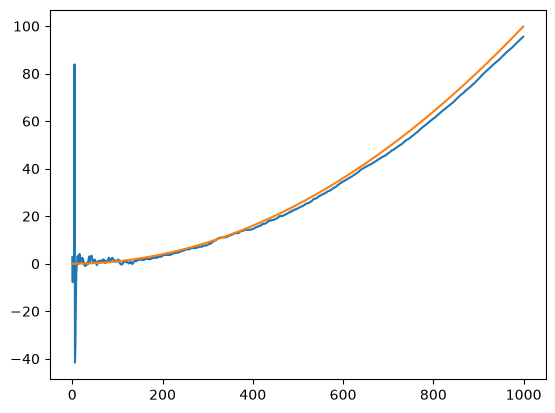

In [20]:
plt.plot(filtered)
plt.plot(square_y)
plt.show()

In [21]:
error = filtered.flatten() - square_y
mean_error = np.mean(error)  

In [22]:
mean_error

np.float64(-1.5626928886286393)

## Висновки
Обрано α-β-γ фільтр, бо тренд вхідних даних квадратичний, а α-β фільтр описує лише лінійну зміну й тому систематично відстає. Перехід до α-β-γ фільтра зменшив середню похибку з −5.8 до −1.6, тобто ефект розходження суттєво послабився. Повністю незміщеної оцінки не досягнуто: наприкінці інтервалу оцінка все ще трохи нижча за тренд, бо коефіцієнти α, β, γ прямують до нуля і фільтр перестає реагувати на нові виміри. Далі можна обмежити «пам'ять» фільтра (мінімальні значення коефіцієнтів або ковзне вікно).